# BOMBcompeTItion student template

<table><tr>
<td align="center">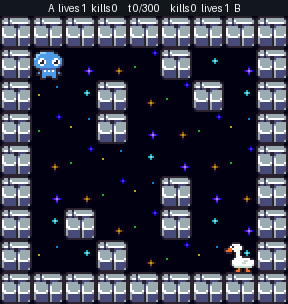<br>A game: bombs explode in a cross; the first hit loses.</td>
<td align="center">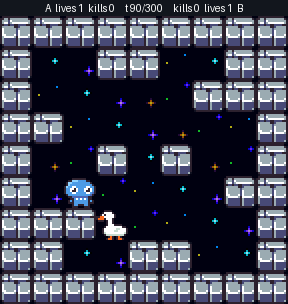<br>Sudden death: at step 100 and 200 the map shrinks.</td>
</tr></table>

1. Run **Install**. It unpacks the game engine (`bombcompetition`), the same code the grading server uses, and an example bot (`bots/simple.py`).
   Read **The game** and watch the sample game.
2. Edit the **submission cell** (`%%writefile submission.py`): the network `Net`. Re-run it after every edit.
3. **Train** (section 5): fill in the two ✏️ TODOs (epsilon-greedy, the Q-learning target), run the check, then
   train a basic DQN. Improve the reward, network and settings, or use any other method: only
   `Net` and its weights are graded.
4. Run the **last cell**. It saves `submission.pth`, plays one test game in a clean folder, and downloads `submission.zip`.
5. Upload `submission.zip` on the leaderboard page with your team name and password.

> ⚠️ **You submit a neural network, nothing else.** The server plays every game with the fixed `NeuralPolicy`:
> `turn(obs)` → the fixed `preprocess` → **your `Net`** → the action with the highest score. You cannot submit an `act()`,
> a rule-based bot or a search. `Net.forward` must be a learned network: hand-written game logic inside `Net`
> (if/else on the board, path finding, search, a copy of a bot's rules) is not allowed, and such a submission is
> disqualified. Rule-based bots are fine **for training** (as opponents or teachers), never at play time.

## 1. Install

Run once per Colab session (also after a runtime restart). No need to read or edit it.

In [ ]:
#@title Install the game engine { display-mode: "form" }
import base64, importlib, io, random, shutil, subprocess, sys, tarfile
from pathlib import Path

ENGINE = "H4sIAMuP/moC/+19CYAcVZnwhFPbcInK4cGjA6Q66XR6ZnJAh4bMZCbJaDIzzkxAbNue6u7qmWJ6qpqqmosQEXARFhFQV05ZRBBlEfFcRHTDtbouh6IIeKyIrrg/rMCigqiw3/Gq6lV3T4L7sxHXLiXTVfWO7x3f+b7vq6I9WSzZkzXDMz3TtpYXCqZleoVCqjbX9nJdabhWrVhBf+Gq/5te0R684+ftnR0rVreJdNsuuKZcT3eg+7a/zqvi2JMiZVjTwpys2Y4numFDGE6vNZ0UE2a1WnCMGd0px7jcmD5p+AV7ejeNdA0nxeauQfhn4IRe+D20ZRP+6SrhXkqKHkP3xpNiA9SCd1NVw02KYlV3vULJqFbhpmqM6dWCTsXh1jGtsYJdkZ1N6l5p3O9tyCjZTjkphvWK0W17UNXWy4WaXTVLc0lRq+pzBSovf7uGYxpu0FDN9dtxdKtsTxagjD0FrchbB2GL/TWuf7EO/3XXNTx3+aa+db39w73LirQbqjBLqcny/xf+r5oX/zvSq+vxf1X7ypUt/N8V1+a+EbHJLBmWa8Ri6+zanGOOjXtCKyVEB6yMWCZqjuEalifW2WXDEQOWIQa9ObFppCcWGzScSdN1Yd8I0xXjhmMU58QY4JRnAKpWHMMQdkWUxnVnDAiAZwvdmhM1w3Ghgl30dGA11pjQRQn6jUFJbxyace2KByTHgMJlAdvRLpk6tCfKdmlqEgDRcZ+KigkYKzRv3BDxYVkjnqBOyoZejZmWwHf+KzFjeuOA8QIG4zmmpE+mVapOlREG/3XVnDRlD1idJsONQaNTLowA4UyKSbtsVvCvQcOqTRWrpguEp2xi08UpDx66+JBmNYnjWG47wgWSF4MWgC4JGmsIHZVB0Gs4oZ6cIhefzIwDBYuMxASyNuVY0KVBdco2TBn1eLJR8vAJFq/Y1ao9g0Mr2VaZcNvNxGIj8Eov2tMGjYXX2rI9AJVBwAWohasqX7njerUqioacMOgXpldXhuNg94BIlmfqVYGEFvurH2YK+t/YK4YH1o+c2DXUK/qGxeDQwAl9Pb09It41DPfxpDixb2TjwJYRASWGuvpHThID60VX/0nibX39PUnR+47Bod7hYTEwFOvbPLiprxee9fWv27Slp69/g+iGev0DsKH7YFtDoyMDAjuUTfX1DmNjm3uH1m2E267uvk19IyclY+v7RvqxzfUDQ6JLDHYNjfSt27Kpa0gMbhkaHBjuhe57oNn+vv71Q9BL7+be/pEU9ArPRO8JcCOGN3Zt2oRdxbq2APRDCJ9YNzB40lDfho0jYuPApp5eeNjdC5B1dW/q5a5gUOs2dfVtBj7ZtblrQy/VGoBWhmJYjKETJ27sxUfYXxf8f91I30A/DmPdQP/IENwmYZRDI0HVE/uGe4EBD/UN44SsHxrYnIzhdEKNAWoE6vX3cis41SKyIlAE77cM9wYNAp/v2gRtDWNlHKJfOBVra13/V/k/SWmpmjX2ssn/8/P/9KrV7XX8f0XHqo4W/98V17mD/Rv2iR2KuLxP38aeIfi7P/73qr3g38OeeVGHP3sV37ahp+1F/N9VX7vuw21tC6y+nq6Ro88/fzhrnzn4uux9z33n/KNXfv99377E2/+61D/ftc/eT9vef61OP/3GJ+7/p8P3/fzU4alNj669f+PGG06JJ8/f/lRmxZNPXzn+s0tvvnjrvX+cffa1fzjr2u9fd3X2vOmfd3zy0f3PveWyvheEtaXniNLxv/qOsE4pztR+/uK+P7x3y0W3bHzDXVf+271XjV/8218ufPTIVxX3+f0pFxx3+nsO6BPn5Nra7uhf0HbPgwd9+rRvHLtg8Kp/OOSCf1+W/NJxDzyw8Me3HfD43+3Vlv7Yhr6r3lFdu2Hy5hMSHedNX/PPux0813H+6EMJ5/iP7HHoM4efc/FIZbj08JNdpeN+/pNbLtM//Rtz88L0Ex/5x9oxu7d984/7n/2xMz/4rZ9+/662R49MP/H4z3OPvP6mmelle37lsNvbB7Q3vPF15+3zpmfe96P9fvrO2DkXP/L7n318U+ybS9dcuv7WngeHZidu6P5+/Kl//MFpn/jtz95ifNf47CmvuefZw+798NmzD03f9G7z7944etJ+P9zX3nJy1w3dt+6513e+ccJz17fdkR27+6nXLHruqmXPn/npE3DB+nr7e27sHj3zfxn/4XFBf5kIwM7wf2Xnqnr87wSVoIX/r1j8P9DH//b+O9P7X3HFjZvP++Kba+PPtN3/7St6Xn/uUfss23NFYnCJ99m1Jz7d9tYl1/dcffXHn907/kjmuAv3Tt4zt/zLzx693vnpb+6evfXLnQ9dmP3NE6ML3ntF9vTL/999P/xuT+c/nvPMs3+fXfDCfgvEYwdd7ExtW/we64Cxj1546YGPfvmjB2++b9HdHzj2vgVtPzu6ePBer3/jbxaec+ojfT17xLuvuObxzEeMQ7532m4//tg5N3xir6N63z7+tzfvvfcBiy9ZcOH0l14Y/t6zX9v3gs+sX9G1ZfXs3LbOuy7/9+73u/tu+fEvb/nt9uvGn7R32/24426vfOXbv/uXbxz0gwcOHbhgv7YLj3zwHQ9sHi0esmn1wML3/njq1KMfmz777tvWnHP8h2c/tOeLN30y8/jq6y86430vvubDC0fXLjxtdr//BST9M/B/xP/irsL/Fe2N+N/ewv9XLv6/wcf/j/fv0b7/tq23ie9/6ANnvavj9wtuuO1dZ/5gjy/sdd5t1Ved1HvvUwsOdmK3Lb5q8KuvvnL097tffmHnU3suvfCsr9w7+cNjPnjxiPf8vz3++BfvGV03/b0vfG3Ptv965qnq9fs9ab/2njN6//DCcz844JEX929zTp1OHXTxg48+9oZTKq++9JjDrZPP/c6vj7397m8+86a29AcXna0Pfu7t9733U3tf2QNa5J19t9y47qSPdt2z+Ns/PvebmZNHh173N588Z+tNB51y5iFt5sX/cHzvtp88/tRD4z0HjkyddfGDq4dvfffdU0c/NvjA+TdO7Hfa3/72t0vSj/xs0Q0HuR/7+1tPvzp/41O/nt277STn/C0/3uOoj97mPXNn20Pvvu79rjXxzTfdetZznecuPump/Sau/8J7PnHoIRuf+6dbv6gfNf31r//LXxAJmAf/K1XbdgrtLw8B2Bn+d3Sk6/F/ZbrF//+8+L8b/HvhReOrmuF/Wy/iv3ZRqTy6/6jYM33RNad+e/y5tVefvfn95z741Bn6d39x0smXLbx81R3/qR/xphsuX9X53O9un+sZH33uvTecffA+2mjtzjtGH2xre/Hh12z57s1H3PKXxTH/KvR/xv+OXYT/nasb8L+9Zf9/BeP/SAP+j9yx3Rz8+dCizevOffzIcqpz9933fssXcl+78ls9Tz/0wgvTf/zc99//E/uQgw8++NWfvPbTLxz/+dXxhXeN7b7H9nvObrt91VULPnTW69ue+/sDzc+d95n/apGDVwr+d+4a/G9f1dmI/y3+/wrGf60e/y+bPvSdv9p+6QfOeni/N574+f0/oQ/+Xt/DbGs7/PLdF55z6/NPt3D6LxH/V+wq+X9FI/53tvD/lYv/fU34/3tPfqTyUM9lZ79u8+uLK2ud1W89eGvljS8eW3jm0Dvfsr54/9DXf/Glcx/80sba/Vc8PvNI9erq2r2O2Htp24XGwp9ftfLaVItAvALxf+Uuwv/2Jvp/y//vFYz/2Sj+H/DpD16uH/jqQ28+ZNW149ev/XX6tf9xhHX25sIhf9j47ba973xeHx/f/wept37g7APe8tae3dqeTe+1aM/HfvyjFs6/YvEfnSgN52U6AdwZ/gO21+P/6hUt+f/Pi/+K/f9JxPbZK679cPu+Z67dv/f4973tHReN7vdvt/1t95Ojjx75qi/9dH/n1ZOfumnV6/b45ZEPr//g595QWXXHE1cf1f+Fm178p4cvfXPbCwsHrDvffvXFd9/xUO6FtWe+/21jd/5w22VfPW/kX3vectse77xw0chFlx1x3EHvOWOBuHvJ8Oc2XHfgadkb29p+f3//USu3XPNk7Igrblj9i5NuH7r8S2vPvrZmLjj94YsPfH7DY9Xb7r/sDW2Xd1+y5bzFue98cXDqg/oT2c6BWx6obX3+m9dn9n7khU/tv+HcD36i58l7Bz7zpekbf374Pz+Wts/61dobt/9hzSWbu17/Hw/+9tr7Np1x6qP/fsqiz977/EGzT+3xo5u/+OJu73Mu2OdnT73zvX8N9GnH+F/cJfjfubpB/1+9snX+94rB/9sZ/0ujV+2fvvo1v0z8x4sbflG4ZeaAdfv0X3XdNS8e9uar3rhxsPPTZ9+0/Yj7Tv166bkPL/pG7elfLbo6f/d2uPb47sLdn//WXlrs13+3z6vef9aVH3rh9IPX/3bfdn377dvXFjeWOtsOu3n22d3O+vrnFzz99vOWveGmu2InfPan3z3tD/f+zYvfePJd29PnnHvw6VfevPWiM+C6rfukw9bte0fbJcXy6MdvuODjh3xy34l3X/KVicO7Trz2q3cduO/dP3n485q5+6UXfPc16bu++ekDD7niN6e9/0OlBYVT/uW1z7wu94GWyPHS8H9Gr1ZfLve/nZ//r2o4/29vb/n/vWLwv/H8/yg+/wf5f3T028P3n/6va+M3e09end4drk8Ahuf2TaU+/r3n37oXXGc/fP5/LkyvOi791c997PCv3dJ92blnnLGg96wLr3jzurees7xr96HHlx5y1APfKxhnvHr7is987PSP6Pdeds8e+1z6hUrn7j96zcKFC7uHDn3LQrzus54YXVvpTKe3/y7dduBYufwHICHbt1/4w4c/cMTkPmObUz9ZMLb34neWPnXp0Nu/sf19T5zmwau7xbU/PeOTh7w+/dOPdO323O1nabs/teDmBQ9VbxvrfFf/QN+L//nEA5e/UNr9Cyfaz3/2umsuGO4vPPxI9tg3z5564iNfnARIFk48dthdT+7pLLhrr5vedcvM22enS78//fBj1nxoxV6L39mZ/uPn7q/gLFzy1dM+8b1rLnv+H645+MIH7//UH5/7xe8Oajv3+jPEHV8eqr2CqU49/hvW9MsZ+vdS8H9lR2c9/+/oTK9q4f+uuOLx+Ia5SUt3zalJAYufEXP2FMXQCdsyhGuWjaQYtWs1uLO8UaHZRVcsO05wzF6CSroU5WHDP04K2ovFZKzdWNCw7uJNrEkUoYwYVEIEZSHHsDDeSBbz7IIzVsTwnoJnzHqxWKxsVNQARa3mGNMFAC4pQUsKuiljCKKbQJArVVv3MjEBF0CJkTDQhj5VxaAgbCIjlraLmXHDwilwBGKGGDc9OTo5A0mxLCwkqrZrCF1UzYpBI8e2YWxZ7DsXZyE6nqfHjuFNORYDoblTk5pWTiH8MMZsFioBiAIecR3/UcV2BAXbyGEkYOClKvDoMExTg4lNwd9EMDL668ObESKyYtRksFyCu6Ma/DODP/E9rnywF5IiDYPqwkCfdvjRzSPC1aLyMAW0dDAAntEMd1GpmCUMCKJFTshpwKkuVKyMeKlLlhQlkEaMstArHoBsTBvOnHA9o7aGWlQurgnL4cKqzYzbYgY2HiyhoGgw3aNaFOhUnOPIKo1CVDUeO0e8Gk4iEUylXFFPL+ueDiPfGud9WZi0y4Ybz4hcXLdcM54UcdifBd1x9Ll4Hu+4WKWGhVZs44Zwz/oB1pprVCtJZV/5829aHnSUTvrzyzOb9TElmMCssvuT9TOBEx3AmYFxO+I00Y8YnaU/crfghXCkQjDo1p8PunE4cJd/h63iLq8DXsKcVDuP9hNAD7WD30ER2AFuDd4gNdCoqUTKNU8FyoCb3K3pJSAPfmEMIYaybi01MlWrGpoGv3pMtwSIZmhWAptS7+Wi4lW1rTHDxVme1Ge5n1SFAvzC3wV4hds9HVYjgpDlZkuetjVes3FxEQ5YcHvGAlzPRHrtACji2Frd87AbsVS0J5qsnrzi+lh9XR94rLgtUbeKRddwpil8sUCzpYIb6cSnTQ3wRkuhGuByoc2A1ma3aenOnKbBQsGM1hWeNPzZiD6HXdL8BU6obH3YOGXKsEqGhs/qG66a04Ys12SpeTKpDM9mQiwRDSNBzG+6CrDOBXzp1i1F/dwyiYpOq2xoVSJEbwyW9SRuu4ZRziK2IZpTRGS2HvemaoajJVJ+LSiP/9R1TfxSYkUUIxvKSy4TVMMtoSkoDRtyq0KMcOASWMnQQ9jGiCVTz0FzEfIQlPTpOJQM+gTuFbyX8f3wOgdkLZ2vf5GbNPLJ4KYdGCE8gNJACTUJVpJuIqRKC/riGiqGS0Yg4aFRLpHth4V2ADGTJngr2XWEdCl8KwKhyrzCpjyMprUoghnojWkx2LRdE+JYIPRBSdOq2MRiuA3YrfwjGWKAR9tfaQHeIRuoe0ePEtvqdwUBKBmGAleS56CM3AF5o2V7kbcIl7rBkbTTlCibRfbAYpoW7JeEMCtNGEdW5ZbCqAIdlIKdUrUVXvrn0P9oK7zMCuCO9b+OzhUdDfrfis50S//bRfofC5iI+cRoDGvMtDBWv1cvjbPEXARlQYp4LtJpAaI06QhY3jMnjUysPSW6BzZ3i7JjAyvVWViypSpFopoGlSZtkFxGkeUS7x/FDAFYwsUWbeD/iVSsIyU228jMMdlBsWqXJgyW13VKGUMVZbKCqBazRngzdgDmpD2N2Q+AQtukyRIMNBBY8LlUrDMl1oMABtqdWZoQZRDfUqDgENgAS1oYs7UqyviU6kCUHNulfAajjl42pwBymcHG9YAfqQDGiGt7HnYOCpCEkKE2UdWEWQWxA/qSqp7MVEH9UdIFVCpdqVWuwTom3iFNx7YD/U2yQaSw6v1ilweBqk9NB9UZgDa9FFY90YTRj/rSLeryJJXo1TXUQtXQx6YMMcW9V8xZGBYWBiajC8uYoXaheZJbASbOnYPw51h69lvO0/KMm+WyYRGLIPhC2VS44/YMq9WG7lRNFGdhmCXd8medG7BnSFQX+piN73FEuL1gulOxFTCDpA7qzCWjezRgR9iJ6eCSw0zQknFaEdoLtJFgkzkGbBZsdGVKDE8h1LJNbdQdd0xrokA652giE1FBoy8FC5E01Clkn7jV7Rq05fBWoFeTek0gaC5vTNoyOEPaMbPHSKUZq6yeXS2KBtBlWIqVsyuT+MYSnbOdiRRp/i6iFkyJAv0amAm5o/idSTjAOUKwYQvm2vBhwqmIkcyBen5K9FWQ7Y8zxpDqD9WxZDIAG3e6K3jMUC5FuUQkxSi7bBNxAWJEtnFYKssWLJRXjYqHqhTP3WggcI+mYqq1iLcTW39Q2yY7hxEkbgoecQnDmpr0X/VZXi/cBi3B79oc2pysWiy2jtVEko5yJuqq8E9eiEVCc+wZzOlShQ0OPwHnTV4/GGgstrlrEKppbAlY5F/xpHzQlUotSsF/wYOU/J/6IBV90KRKqr7KoiZVusMHChyhLYjTbWlyGqRUNjzSdZLwxcstOJZ2+tkzcGI/3HTQzabe9SNw00k3nKwkK1bQHVHzrFgJvXCmL5wNDeV3mC5tWbv84f9No2FM/vD/phMJmudygWa6XMC5xvQyUtaPUdYwbJdHkNoy6OcOSyGYwQ2CGdwQmDj4tcGW0GBLnGpY2RFnCuRGnhTiajwVnOxLSsg513OSAiYWNQxcZIBw8aLFhIpJsTi1WJDvG/zsWrx8cfdilXasAaLhoFVyEqQGzIcT4C+Xcv0+1pFNAP/NR+0u2BsgpeOYyFpws/ndUAfUFJJR3wy0EiswZWHEQPrHSZOIyntIGd2QeayhTEYBJWaSAuTW8RD1a8DEzGLVCLrhMthVA5QkuAO2IL/6H1F+oWFTQDKrM2giJr4zmiTab0lbILFSf6gd2GvIBYlRYhf0t2w6Bu8ZMsj5AoRftxPrMkGvBfKAkEmcijbqclLA4A2BdMmv205rAoNGfssTVjEdmC00HBJp8ySh44VWiH7d1LWn07RcCgvJSF5BiZUmMf1VyCaQqDKvxyUkpsG8Qk6chVUTwYCpYjDgdBowgEyCaBrEva4RskXsrpKjc3Y7FWEUIzKjCFmvqPG6LQhNwkpUJdhEyjW5vkTxKywuIB+iTcHw6mPBDk6HO9g1YQHqOPlO8ZgMtJmIhdqHkq21kUXwZyAwTALfoRcoNumkilJOOxwEbojqHEpuJKTCFPAWSsjTBSVToUaIDktSS1llUluThLAZwZiu7GSyWwPmEA3IB0b5dSR7YKfQnx7ImaPYymhwdsASSlZsxR+sv9MRAJCjcgmRgUlxrj2zMh8q31hkAt/CEowZSJIZHrJoZSJ2MFwRDRvPpfPwuuyIJWKCx5JrpyclfJKIVAJSQOPPeflMg6myCNtjIvKUBpHSy2XNS6hHH0zhfKaF1qxgdgZ93QL2URrYQYLoSLvQuhOpwAzfxHre3EQe2N2UwUMr+DgDQ9al7CmpGO3gNaE+oxjXWFaU1ivHoFOxoBxpyv7ChWwGDdtskaTbOvM3YHdWdpwaoj9aE4Mf2ryhXNWwNG6l7j2tBhSA7UibUcvlgEaiWWVRnHYDU07gunm6RekG7rmtfNhYxbTKtNuATmkOSUEpeGTMaqXxBJ8+8VOiwyBbGI6OJmiGSekp3tUdx20S9LutbkDEHXFIputJw6t8Bm1oCEdqzPC0eBfm8Atvu+OqVc+3JdHwU+64XjPE4bCfgzlLhtOXwIbRkqWFVXI5klLy+RTcabzHlLeZpIgWqMMdRzeB/Z2gV6eMXsexHS3uU3FfHHBPmfJzDTLGkKKhO/aUVY5HxkE0ybQis8M5Av1bRNBsNvIEEBSpmDWnjsnlJXbrWtsZ7JV4US+rsk1GbFWqb4tLm3a4dSWOMTOJvGIxPytyiineP0uhm3y0PJknG63B9M4TqkmUHpWZu67Xq27daVIBtNICza6mmOCVp3VWSjZe2zBW3IdMof1Nqc5dtIKUNMpmyZOCHfJNrLi1bpsTwyC2kQlZANnPPebOTN/pKFJqumVf/8daxCebNLkjkOEdNQ1/Ocujb5wB0cXXOoO2k7BLYbcYUqGnSWp+GpAmZgY/2kOuRhAQP85HCOtg4C3gH69Kio9HsGWTx2h6EWLp4zIubrOtOjRloWFJQTT2GnBJfI43O1yQWoSmo0Li/25PKBsZEaWG1owIOfMPBqJgTJq06/Ckvpgi8QjRsUZtFANko72Rmka8AgGsgW3qWEfqLaRQ4eRQy8cqWJUK5NmQJMFy5mp5omCRvhoZcPgup9TETYLbVKslFVxBXqepM+JhalaizFy5wA+wlp7YyXzl1cWUDSHVApLs37XXCQw+gCIoEoJCeJNEEakAIpKkfAWJJlqTs52cPLsHhRPT1CIU8oclW8EZpNMFEgZ4OPiWldRgD8q5hhcEQz6yXxT3iyZjIfKW89028mKZr2YrUxP4eZgurWd/w5aPUsacXwHkMWyunkAuVftQKSSeLoVQ8elSwFU8cVy2fs+RWK6uIoIXthhsRsmwFc0nfOeJI+ctBJs/3WTSClxIk/WXL5+vgXDRcT1530Qpnwq83Bj+EdY85KWRccxDwpNRAgxdKzsUHtSffXH3ChtSRpkUE0xGI3RzOKIokuo3wSmNpZkBVW18mk4E1kBi+msCQyeb+tDON6+Zz7fxqdQXW0VDGFE1X6XFh4pkkVTVALk3qEYduabRR1BG9kq9NJl8lltKkpOhrhdrTs9ghWsau1cQAkfpeIjImXqMq8PqRjgIcKhbSvuEhks3FKIc1kBqZqnPWWJkNGvQy2wjdabNN4sUMGiUSFKeJDeq2RzxJbCMw9gpzL4xl63qk8WyLmZBPNeLrjaL5HUZQJ4ATY0ftOODEnK8WZ+ur62Bam043lx4ZstZ7on6k0iE3Lxo29VMU8eBOi8YhWzVk4SgzHH1T+vEsWjXgAnz9GyNpRDY4LBfdc5p0q9yvhwOkUn+/PBIFsd4WfPlnIzk0wQgilkhhKgaldCmyXp4Irpnkr5Srofbh9RshxRsqEpqteJHJM+0sio6eLRD6rcTPco27Kamc+fv90rQAR2SRTajzw89ZTp8DhusjjST+vJrkuU+vEfLeT4q+43g6Zk0ApHg59pVzC4+roOUUw7teW4qqDVk8AlIcOqFUnBwNpNULHh8+EDCV5BMnCeGRGg+S6ODwMkIeduRjBYlBEX2wmpg28WUPmZEOW2jfAJCfRLlJvpLf8KVOWXKmCLKQcTQp4rJBrBMz5hE0x0uG8OCXDtsZ2bcrBrcWqbBygLt0xsilA3CJ/lSiUx2BxQ1gcjdXB4p2SCAW3W0Ge1X2YhhTOUX3LCCeGyGigJGlcVpWWwr8oJnbGmU2JLzZoV/h8OI0ukdcoPmHAGazTR1ugvkRrJfYWcs+zd4WEV2Q4hNM0TjI5ROmiajWAMbWRqpyVgwiTpZeFqWVG2WaLBqqjqx7KmYCfhBvcwtAcYW6wcRkFm/pk/H/aYVrdp3JPNJJg0PdeLIwE5EvJQjq6ENzc0E5nO0NngGnsvR6WRUIGGA5nNSBBkfVFzyQU4qHsiNfoqheQi/b4B4SQcDdlVo0kCEtqGktGf6B4D5Jo6MKoVv5s9YR5KjZRZJCzrbvVGVreKgfZ8CeUqjGiBplnq7hjb19Q6P+KfhWjv5qM4VDflpDGgOT+OpdF2HZKX3D2jYQp9iO/z8xvdUc39M9iSbx79VIkTS900lSjm/Bys1LF1g0du2vYGPw/RRGzvg5UwZt+2ok51S2PmcSlUEQGau4gOtLO8hDbX2pOJlkWjuX0oqjeJFKs8S5JeNNPXQALdiiEqBTARokQ68PFgRwD3vP3HUM3qPTjJ9RJJIhCKkNPEHln3uDcaDYwpe1j9rz/tnH6pK0OTsYyKEu7m0QL/zkWAL5vB2RSo6ydCHx9dU3HBcwZgsaQcnIBKRQ5Icy2Vspg6PPyxpmFafREIwtK0Kg5H9his0i67NSFIntkV3TG7ntY4D/c1XP5nCzOaDKY186wrDaNikGFrWWP4MJw1P8JMiMBuRsZkco0j4QUMz9qN4SOnyENv3voo6CgVTyhJUVmwt5gjF86G8RGErTAbyjG7cI0x2PjiNInMQHd1nogIv1QbimefDpUAspr0WvmyPvmzPN6iZ3BIT9bwqGkelYiqF1Dhfb7tDoFM6kDhQ8PXIIZSc5RRPrmKaS4olVC0f+6v2/8Rvpe1a/8/0qvTq1Q3+n6ta+T93mf8niyG08qKXDHd4qAVixDGzxzQ/zAoIEp2E6tIRr/3o9O03kXsbsBZbWIZJvo9E0tEjTLdienlatzzg9mtEl/SZwfMKFAva+UCum+5XJ8XqBAo60ofDj9QDwFIsk5I7TN3urfvIX3hUpUZQqC855KIT/ZSE7ztAQ6LT3zFzWgpm9Az6psbwY4lZJQAvdDagNrORDqjpRf55SzDT83q+gTRaNeSRhu/5hrEx8/rF0bF0ydhBbGXjhxdjseG+d/bCII6JgTyNbl68AEmh0YtloiMp/F8+/ypMmnQYgy1IeitpqiwZES3qn7Xn/WY4tZjiVhFtbB6uju01MHZ+KJmGFOnzuVI+6KtYkX0kebMlfXaZZU8TUtpl/7DksG99vX0rlc+I9LYkL4CWoyeSWTVVy8nWo6jkqMppUaulRXqq5uDUSKMSmomC39jCMl4JaTlqTzTaN8PhWjDZefi3Pc+uV1ZokwShKvJEjrzZyYNh5Sw+p4RfPP/Io9sbivLQJGO1IowV6/rTDrpLwXBLes0ogLJAR1taxEbAsX2BpLMety67wiQlNWlwdMOvCybZFZpMH/aUJ2VFV9oUyBykF6t0sI6Hh8f7Ek8Tv9Dm1ozAoYI3ZgTciDUDv/UHddUNRnihzgge1Jf82ce+cDnKaN+JKD8s2peS8qQJGg5UFn8+7Qm/E3XiCJEQiEaMiikbpeNo7BJlaCpHx0IrVjTYX8Pjdfa8iw6uK2gSG6ISCbQsKs0ivuJz8tzoRu9Pcaw4OuN715VsywLChmZJKJYMTjAo2si2RQld4eYHapGQ4QjosIDMxLHxw4j4+cPyGO8CdOBizz3cMcyC7KJdnhOkOk+VJvyzdtQ4yIVZXa1qVdvRxg0mP3S30JB4BqsU+bKspsT+NXNSUlUn3x81QIcun1G4c5OTBn6ukjix9C/Sdu6t6iZCnXCHHkf+CdA8RLc9pOMNtFd9x7pBTYfJbzB5Ro5M6AHsvwgvyQdbhPC6wh6fXAK2CzbL7n6GUSuQsgjkGaee3Y8xyFbrYPblt8vP1QdUIBG61BWUkaTTBRA7FTJbBs5gemjkxQOJKcuEGpNaOgWNpFOdq0KS7jti5XJ4jJUXS2hOkHb6T+AXbWJ8FzBXPL6R7+tgCUqobchWm56x0aQ3MAh6KylPOG1IfyIz37yIfwgDOwVRWE5GI9+Q7mG0J6RROdJ6ormJVeHT9cd/5ry0LqALGDiC842ebuiXyAaieIr93maaub1Rc/mGZnJdxDu7kHcm+Uk3PekmbpoV8S4M6++ON7OmsoksHk+dbJsWBhIk1B6xMd/FudGZxbLFtF41yyRlV6RvWISGKLLpTkiI4uUOGD9K5UZZZtcbqQhKz3XGIik+atLrkWlMtpGW+cshBSkZydyK0fy/p/97wMJfXgPAjvX/9vYVDfm/Ola18n/tMv1/k63TN7CLtseHuCia4QPUJUG4NrwZVCaCU1ZfbeU/VbOYmvLMqv/0ZNe2/N9I9BrU2pReLPkS+TogzSix7zzqC72CjWqZC9Z0bxz69QsNwm3z4K95deIumXCGXMii6YfYWAtzUqjZVbM0p1XsahnDDDiJCnbG0ttczYgYuAepuGD3dur5WK563HJuKYVfDwcuETx2p4ryS9vwij1/1tkwIQLkf1gEz8CYG1A0Q3GOawILQDAkZJQ+Ak/dpa6Js4OpC7jochEPeieWqTV7kUgZs5g1Bzg+MdSwTARGBsKtGajnRtc/hU8LOOwCglwAbZOCPbWK7KawFT1WQHQf1xBCEMaAvdIvaWguw/Q3NsvPuWHsQsN/EgEcKVwpwwHwoXcuq/GfiC7Gj1K8RIElwkF7EO6OjNwB0jovua70+lP9XtFUkqg7+oS1GfCdX230+eRIgYwafEQ6LVmSyAsXf/mOq2TNr3KcJh7oIAb6jrP13Do8H/UPnCgKQTlwkod2OXKTqyk+j5w0Qjqz5elMawZ1aoLFV8Zm8IFmTAO6c1jxHD86eYrjoULJNzgszOWWyHM3/2CQT+vy9UdyBEDkSE45NI2TFh4AztKpKueG4LOPplLVP8mjmmpujLCInyMjLMIpMpQicjkQBMrqkQjPOuQr8q3xVy1wK1WaCPJ25AKP0KQInTnrvEnlEPwTQixfIO6LDrbpTEAbaVe2q/dNo15iDfmfeBOGVCsa45cUFpL3SFQk/EM73Jd8eac3ROqQsjbmI0waiW2XHyrTjnfdSdULnCPqLNNFXx2afGqMo9EZTDT7VEFfd/VpI/QXQJOxeOvwQL8fe6ORjsL5vGaM4nJ+nBr3JqshiYzYeklmlfZi4magOyh4LzVXtuahMhRkQsk0czDH0YZpZ9KoYOKQlUw0f3ISGjxD5JWK+rQQtL6lTYE4oFF1qWaatOM0RGsQ0+BiidSMA2jISVeQZ6fKwDjd5mmiAtShLVN/kk59QImt/jm/Ix324mwxoyf8E54Fvu70OLhTktw4fgRJPPBRDsrS3bb6o3xSU3wYHRl5VQ8mTymU4h9qpqcIq6BITz9KbVivGN12SOhBk8NNSUzRQ2OWZPquzXScHTdwJ5Uc4HRQlNkLpTYoGZRvgYN4YA+TFhgL9xjoZxPywAFkMY7g5mN/NXVdCTRGFNQoSQMeijA69dskbsEcTHLwv2FB3RKAOGd4a8SoW7VnDNcbhWGWbEdGtcqH2D9wfkyzt8NwO8nIS+gOgOJPfWgNgeOnijNQ2/Vv/I4osV0uj3aUMMqn4KeV4rn0Xf8RHC3sUo3woY4kULCWrvRzcZoDFPXjkzZMBUa0cqxs4qjMb30klP2oYBCEDEUFhMklujOmGiw8Z66pKxbaPLCGxhWCIrxDRG+wUWCNm3qv8/Ar8a1jhqd7nqNh74sLhVOm9CqiaKGwGNtPbAOkNA53tsUTzcAguxS7moVjwp0gMxMW3UZn3dCVjpaqqfegbF45aA8Xhcy3WdqpqZrhVAq0mzEHWpiWa8KncdGdoPSLydgYwLoww2CXoauR+ijZrEuxjAGKUGObXThM17TgJaak85NTauQobNVS8NcYwzSRVDKNBk0JMPxa2XQylERh0c52tLyYaYfrAxZv5eqwmkn0I5OmdGpZpJetjDd4KKrz3yT2e4jIQCYIpA5Cy9OxkHlFn83AlNSVwmDa6KOqjfpb9BmjYfSZXJgMp1jDxykOFQe4rDLSDZU28cEr4aOUx6WsQlqhn3YUZq7k2c5cFkskVMHKNRzTcDUgqwWdaRdmEgJh0r8ZY2HIDI5xG6OKZ/Rahn0J2Wyp2PB5MpNyUvNRaWmU2h6tV6dn7IjGiDmBCDyZUrdLAihvu9fIJUChCUEZTbJ8XhpHwzEdsrsy2QCnHIrEJ/tEH4QYhhFdI/1ficAqboaWaIJWIWYckZKVGT+IEAAUjCviSNHBErGMrEKDPpbPIVi4TCBhURoJL0gYjCzNVNKDkvUBpDPJcTVeKzkJiZzSXF4ewdDpn+/1m4/kLWwi/+1UzvPrsqSG4OTSeaQ0dRIfvWmvexMR/Gb8YxV6LV2Co+fAnFe5yOb3MLQO2663eFOmVFq9yCREC8mY2qWyT44jo4J15aRQujSrxucCIQz1pqbVEPWxkj+0bHTxZNsUWh+WktyhrhQTiGhj6CbQpMGQfcPEyLu6IlGS74T0HmvImzruJ/m63yzf5TJiJQBBp5u+WJCPGsppDWL/x+2/ljHl6NWX1wC8E/tvZ2fD9187063vv+0y++8I6eeY7W1Gn4soNxbwKtuZkDRbCzyhSjaTXoo3tD0DmCJLTdJba8xhizJmfEP7ZCzWGyTtDhOSI1ppvpRZA7XUsUsgY+Ndv+FRicBMxowP78fNsXFEeLeEMROyGfR/1UsT0JHSjunKYaF7gVY0gBgk/Hw8/sgo+DkYV19/Yd3Grv7+3k3DYlYcQ/+ZVm0KyMmkDkOmfDF2RaCYAepXEY/j0ROfjXyaZXMkJnRcGrddI0y2LrtLpMSwN1U2UH8j9ZsGSr50jk4x8muYqZdt9vGhMsqQbIfFIRhoOHucTa9bMTfKKSF/PPKD0IMBy2xMGJmBThMgb7IMjMvl2bVlHH5SNScM0RXT0CeQPI2DM0RqjtMoksShSwtikBIFxkje3jwBcvUwsVq4TDQt3TFty+Cxy47jRF+Y4QtuOLeXzAu3Y3+4Zvb+4GMBTml8B8Z/xeMnqXq6x2LrN/UNysQU6DCQFCuSojMpVpKLAo6ApimYZ3Z4RDnIFcFgaD3V8axhTZ6cG9GZG/NPStnUX0TFFTxiVx6pS5zIkR9+gI1cxAzPp5BZ7FH+ar4VAmnQrEQ/UFAXqB2mC4644KtO2dJiYiPjlUGqgNmaJV3+auQDGN75Pt6+GXvJEsxF3DyGB32wXPbCivSYy2Qw6xz+m/eje5rE7QBMoSM65kfmcJ3gMfuLJ3cY+bJkSTHpW9Kxou8on9jW3FU+sU1ZT+niL9U9qVJE11iN9egKkESijKShPr7YlK2ZrD0U4sOF6w8GcOPmFCUz33SN21lIV5XRWCygeEG2Q57xpBpdhIFI+DjmT3RSRMOPKFJpLsgrydOebCxTl6o0LD85J82CyUh5P5ahQmkzgqajZeuLqp1wlTLqNI4CkJ+LRVaaAYGZogK5pboMKjL0CijC8g787EFFEvVZL3jeiS5cQqO4V3QOK1WBzksvKxwbucYpY+PeYca4e3uqWvaDHfv88Cy0Jlr2TDjoSCNhNpkmyV/V9uDfZg36E15Akh9P+u7PM+N2lSgMpqDjeIs+CkZzPZwjbEksDzPwxaRt1YhuCX9F6PgGvyKCLcAGmsDtDSAQs2QnNsumbsKpQhfIsDFsaTlGwi1V8yBOyiC+CXIRZZ/05gmC5cysoehBaZsFrs8OpeHURjpVHMGpt8b9hN6K0LUKphLGRNqtb/exfe95T9k1lPlhGWeZZQ6U4XGqEYOY9DURS8RUsYRJsX8bpPyT7H2xy/IKkGKlUlIcA/8PvEmpi+Zu0aFLbvf64Qynocuo807FtyVJOjHQiobzz+NDwihjkXgWNLb2SSnDpPgB0MfK4VHNX6bLdb6pX3Wj+/Uu8LQORcNQivDDEBQ/U5SHUiOG5dpORLRg8Zh2DPldqqJxBrBX8iBVAkFnMHpOLTfZZdKe51FvfDSxbhzQzqhijkJX+MVzE3nOZYyWWdxFFAVLLIuOkfIgqs+iBZQTmgbZqKUeoqa2TCjfXkoGPpkR7pecV6yYL8pwFnekRYc3UPVUw7Fd+d0T2J1oM8zCYxprZwcbpCySNK1ghOxsOhsGsmXykou6/huKhwuklXyQpHdWyim5UGQJX3pq7B7QaH/C5gnjkyf9VpjJNYhDTnKeBvLbliK2ZFzN/GRxgjwVNQKP4Lpg+uCguyGDZhL93CPe9E2j9ctNGg0OVXJlP08K/kzCg1I+tGBC+x7D5HsZZJr6zf7JoMGSSCEiH+SuQZNTw/MkEXJP+qjINGLpWCQvhbpAYTe4IXwpiBJC5GTUdZ6/ByZ9XUPxJ5/zt0G4O4JO0bxV10DsJcxCsBvnnQ0Gk2WRcC7aX3LjtJ131Hoo6tQ3r8wQiy0SqbT6PGrLaA4SsBB1byIRsBj+I62D0DIJMSqWkloUi+z0uhxsYS1yZg4LW3RUD7JUUlrjiQcp0o0yzapaIjRVGlGnK9RpmuxoGTwSZe3UOw/1NLGVwNiWaMQKHgcCrMy2L3JJCVam8xKNKbp8fZLzIQeNTiQ5V7Akw+SslMdMX9wSsV/+uSxS4kgRtrrjRFVNc1RxQbJEKY0uZViOFXWZzxqp1vyZqxrEgFKY3rf+gl3hy4fRKUUwYpHP5SBjJtc2MmNg/BGIPKUJLSdXpCljyQcxJ2QEczULE3WHskB4djsv5w/lxVW++sltUYdooNOa6KEJ/GwFmqwm9bkgboaV5jVK4mz67AS7KQScuWxMm/ThLJR/EeAUlIJxgQiJkU4pfs+5qCmJroVZCEPxJjB3JXJ4ppBPebbGdUIHGOXM1kabnUaQcUYCFWu4A/g3l46Y+OEJulJiXllKcL8qgQV8V5B+sozzkV0wl2iNQ6gyO7dVJiOWSjGCWqX84ADbSRe7bNxLhg2Q2BOT39jyjYB6EY2MbI2lw1JQgMamJvFbIOzEyXZKXMiRLjordkx86+44l3LdJsqGP+u9KqgkH8eHUGXrG3jJPgU8Wtqpll1A23E9eQqCLkLrCqWu4d0/L0zcXwpmBxl1IiFdBlpO/zs4/+HvdO3K85/0ipWrm5z/dLbOf3bR+U+Po89IRzUyMKOBAg8aXHIvmdTHjFSsm4zJbg0PJEDPXAfag4NOzxwFX0WOq23uG0FDJX0/flPfut7+4V7Ktc/vU5PIPkAVdACDDXTj8Gy76i7HQ+PCpA647GHiiVRo+q9MWSUq45vvS5ju7U+LAKDCg32bgk/F4HCS/AfH3eyUYAM5AHYND/eODPue9gV2ai8kkG0hpV0u4jzUuG/6lR+wC93J+UsAnmS8Y45Z/lMj19h/IAxfUyPu6hyile82QkdBeF18STyo6acxJBWwqUP2PI3AGDD9EadDY9fOYxSnkZq0nCSivgz8JTnbna9VzBnvp9wcN3T62mLcy25lj/Zt8isdYqvimZDOb8uo9+2o3bLnw1bF7yEsxvdQLGIsj7/LkoF7OeyYQi3nC+VDkCmFz1refWxBYzzQPNgT0WRo7EdN2ytF/+YjyQ22YopxYzIjS6DJUKskUsDEgf97WnxoQ3dXnOI5zFMNjdpHz7UqWju5Sn9v11Dv8AjDiAKv4I2aGqvaRS2+JFUDqTM8j+DvMaohDgHMMN+rVhDgYWanQK7RNibFiUnRmWACgMYgzN425YL04kgJJDhkCu15PC9JKpSNzlOCu0YdoEMG5WNkMo/KMmZo8KDz8L6hzFRLBE8AtrZU1D+nrw8dnRQdHfCfvx+RmvitIn6n8B8NulLcNmtT7MicJFxSticUA/SGBdIk4CyDQz+lOlicEIZIUdlLXRh1AHkz28n8RUjsm0JHQA7w36pht6uhewQHluZIsRI1KYyjoZHU2yxD8pHD9020FWyezFPzNREi9rz0JtIWh3Gojf2plIebgXeFOAwurhfjuTANY74eTEqOSHQ3WCOoRX+W4eFtdLngZwdFsDohLaPvTVSr2fjMOMASx8iF0rjtZOOODjcV2/IKuC5Zf/N2/k8IHw2KbZHhsGqR0Uj0QiLYNQ/tm4fWyQRcPuFczj/qdF0u1VifSGhjb/RYhj4rc4wYMmOWQV5HNObpxV8cFuxNufNN5uRkZDKx3hLRocynJJCKlZaRltVcfdoojJkVjV33pQdoSLbyHEimBrtAb+HXklbIpSBaRl6GTHaQ93NnFYWgcid5pQY6AiIMFLiWZHAAabLsyM1G+gIXzcoa7RkAqgwaI0rV2XYQa3GwABOoo7Zdy6ZfIXoIehwud0Hyqb7sn319qfJ/56rVq+rk//TK1a38X7tK/u+d1XH5yRlSDKEkZqIPTQ0DEuGZZ4O8Ak/YzQg/ygnPHSxW/1lPJeZL970aUrE+ikYpGyCuE32szgneb0GsMQoV5epcqklOrNiO0nxFYnkDO41qoWkwcyg0eRFF1OHxFiZG9b9o68lPprJxkiiiwABpzObD38fE02wL04PhAXKYQbWmz2/yaNKpETjEYfvoPufx97npS5++QcoKbEpaetnKRCqmNHQiRW/qk6LPjxnFezPqEHA8TEfwXRiM7Qy+ebmm4ZuX4VjQvI/l4G+J3N0D43NoQ0MbPZbBH0ohslZHwTTlsZNb90E+AAeN9MfTy/Ckwoz4OFEkbOi9oKk5gBMRiH2jPokLfNQixQ31tIXOVSL9ZeuOCiPQ91XqPrbrkrnKP91g6Y2mv4+MouQeoVvhR3+T/Mi2lK2yiHcu4FJV+bqg/9Vg4FqsY/khc0qMnAyMC7h62CaeGKDlE70u8GP2tIJoXOd18j8YIFd0mb9s0Q9o+G0cK4Me5OkMjQ9P//xZxoApLhB+iXEHIUDo9aZO6gDOzgwmRgGNqjTBlk78BJ9lmGPjRfiFeBZ+rRfT0/AyWIbvjUK+JOhdkVIiCEBoDJLD8iIr+U2bbAYlpY5jGIW6XKdBvlMZ/6N+xpS+fRkZsvoNU/l11Kbv2d9xBwX4Y6fye6pNS5BXIRVRS+QbMuUQopNfFm2Gpf4I5CZYykOpF/kjuVeDDNkZzmIY+IDtNFU8KQ8+sfGPzgryU2PUFj74n7SVxVSzdeQnkan/9ONLazlc9yBdrO8YF+7XzeTUa4UZdeirIMEnSSmnAzp1yph5psJWBOXhTdhVU1yRKbpAXDZLhhYW3mFcV8t+3bpaV+tqXa2rdbWu1tW6Wlfral2tq3W1rtbVulpX62pdrat1ta7W1bpaV+tqXa2rdbWu1tW6Wlfral2tq3W1rtb113b9N+GOy1IA8AAA"

try:
    import gymnasium
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "gymnasium"], check=True)
shutil.rmtree("bombcompetition", ignore_errors=True)
shutil.rmtree("bots", ignore_errors=True)
with tarfile.open(fileobj=io.BytesIO(base64.b64decode(ENGINE))) as tar:
    tar.extractall(".", filter="data")
if "" not in sys.path:
    sys.path.insert(0, "")
for name in [m for m in sys.modules if m.split(".")[0] in ("bombcompetition", "bots")]:
    del sys.modules[name]
importlib.invalidate_caches()

import torch, bombcompetition
from IPython.display import Image as _GifImage, display
from PIL import Image as _PIL
from bombcompetition import RULES, Game, SafeBot, legal_actions, random_rules
from bombcompetition.neural import CHANNELS, IN_CHANNELS, NeuralPolicy, preprocess, turn, turn_action
from bombcompetition.render import to_rgb
from bots.simple import Policy as _Simple


class SimpleBot(_Simple):
    """bots/simple.py"""


class RandomBot:
    """A random action that is not blocked."""
    def act(self, obs):
        return int(random.choice(legal_actions(obs)))


def play_game(bot_a, bot_b, rules=None, seed=None):
    """One game: bot_a plays A, bot_b plays B (Policy classes, or functions that make one), on `rules`
    (default: a new random map). Returns (game, actions, bots); game.rules, game.seed and the actions redraw it later."""
    seed = random.randrange(1 << 31) if seed is None else seed  # draws the hidden bomb fuses
    bots, game, actions = [SafeBot(bot_a), SafeBot(bot_b)], Game(rules or random_rules(), seed), []
    game.seed = seed
    while not game.done:
        a = (bots[0].act(game.obs(0)), bots[1].act(game.obs(1)))
        actions.append(a)
        game.step(*a)
    return game, actions, bots


def game_gif(actions, rules=RULES, seed=None, fps=8, tile=40) -> bytes:
    """Replay a game from its actions, map and seed (the engine is deterministic given them) as an animated GIF.
    The number on a bomb is its real fuse, which the players do not see."""
    game = Game(rules, seed)
    frames = [to_rgb(game, tile)]
    for a in actions:
        game.step(*a)
        frames.append(to_rgb(game, tile))
    frames += [frames[-1]] * 8  # hold the end for a moment
    imgs = [_PIL.fromarray(f).convert("P", palette=_PIL.ADAPTIVE, colors=64) for f in frames]
    buf = io.BytesIO()
    imgs[0].save(buf, format="GIF", save_all=True, append_images=imgs[1:], duration=1000 // fps, loop=0, optimize=True)
    return buf.getvalue()


def show_game(actions, rules=RULES, seed=None):
    display(_GifImage(data=game_gif(actions, rules, seed), format="gif"))


print("engine 551f8ad1 |", "torch", torch.__version__, "| GPU:", torch.cuda.is_available())

## 2. The game

A 1-vs-1 bomb game on a 9×9 map. You control one player; the other player is your opponent's bot.

### Board
- Cells are `(row, col)`: row 0 is the top, col 0 is the left. Grey blocks are **walls**: they block movement and stop explosions.
- **The map is random.** Every map has walls all around and is the same after a 180° turn, so neither side has an advantage.
  `random_rules()` gives a new map, `random_rules(seed)` always the same one. Grading uses maps you do not see,
  so train on many random maps, not on one.
- Player **A** starts at `(1, 1)` (top-left), player **B** at `(7, 7)` (bottom-right). You play both sides during grading.
- The walls of the current map are in `obs["walls"]`.

### Actions
`0 STAY` · `1 UP` · `2 DOWN` · `3 LEFT` · `4 RIGHT` · `5 BOMB` (drop a bomb on your cell). An action that is not possible does nothing.

### One step
Both players act **at the same time**. A step is resolved in this order:
1. **Bombs are dropped.** Not if there is already a bomb on that cell or you already have **3 bombs** on the board.
2. **Players move.** A move fails into a wall, a bomb, or the cell where the other player stands. If both move into the same cell, neither moves. You can stand on the bomb you just dropped, but you cannot step back onto a bomb's cell once you leave it.
3. **Fuses tick** by 1. A bomb at 0 explodes.
4. **Explosions** cover the bomb's cell and up to **2 cells** in each of the four directions. Walls stop them. An explosion that reaches another bomb sets it off in the same step (chain reaction).
5. **Hits.** A player on an exploded cell loses a life. Both players can be hit in the same step.
6. **Game over.** If anyone was hit, the game ends.
7. **Sudden death.** After every **100 steps** the outermost open ring of the map turns into walls: the open 7×7
   becomes 5×5 at step 100, then 3×3 at step 200. Bombs on that ring disappear; a player standing
   on it is moved to the nearest open cell inside. (If nothing inside is open, the map stops shrinking.)

### Bomb timing (read this carefully)
A new bomb is created with **fuse 5**, but the fuse already ticks once in the step you drop it
(drop → move → **fuses tick** → explode). So you never see 5: in the next `obs` your bomb already shows **`fuse = 4`**.

**The rule to remember: the `fuse` you see in `obs` = how many more steps until it explodes.**
A bomb with `fuse = 1` explodes at the end of the step you are choosing an action for now.

Example: you drop a bomb at step `s`.

| Step | Your action | What happens to the bomb | `fuse` in the next `obs` |
|---|---|---|---|
| `s` | BOMB | created with fuse 5, ticks once | 4 |
| `s+1` | move 1 | ticks | 3 |
| `s+2` | move 2 | ticks | 2 |
| `s+3` | move 3 | ticks | 1 |
| `s+4` | move 4 | ticks to 0 → **explodes** at the end of this step | (gone) |

So after dropping a bomb you get **4 more moves**; when the 4th one is done you must be outside its blast
(not on its row/column within 2 cells, unless a wall is in between). Bombs block movement, and an explosion
that reaches another bomb sets it off in the same step, so a chain can go off earlier than that bomb's own fuse.

### Lives, kills and the end of a game
- Each player has **1 life**: the first hit ends the game. Nobody hit after **300 steps** also ends it.
- If **your** bomb is part of the explosion that hits the opponent, you get a **kill**. Your own bombs can hit you too, but that gives nobody a kill.
- **Win**: you hit the opponent. **Loss**: the opponent hits you, or **your own bomb hits you (a self-bomb)**.
  **Draw**: both are hit in the same step, or nobody is hit in 300 steps.
- **Scoring: 1 point per win** (the opponent's self-bomb is your win too). Equal wins: **fewer losses** ranks higher
  (equal wins and losses share a rank). Staying alive is not enough: a draw scores nothing.

## 3. The environment and your bot

**Your bot is a neural network.** You write `Net`: the network that turns the board (a fixed input, below) into 6 action
scores, and you train it. The way it plays is fixed, on the server and in this notebook (`NeuralPolicy`):

`obs` → `turn(obs)` → `preprocess` → `Net` → the action with the highest score → turned back

`turn(obs)` shows B the board turned 180°, so your network always sees itself starting **top-left**, like A (every map is
symmetric). You never handle sides yourself. `obs` is a dict:

| Key | Value |
|---|---|
| `player` | 0 if you are A, 1 if you are B |
| `walls` | `(9, 9)` bool numpy array, `walls[row, col]` |
| `me`, `opp` | `(row, col)` of you and the opponent |
| `bombs` | tuple of `{"pos": (row, col), "owner": 0 or 1, "fuse": steps until it explodes, "age": steps since it was dropped}`; `owner == obs["player"]` means it is yours |
| | after `turn(obs)`: `me` starts at `(1, 1)`, and `walls`, `me`, `opp`, `bombs` are turned for B; `player` and `owner` are unchanged |
| `lives` | `(yours, the opponent's)` |
| `step` | steps played so far |

**The network's input is fixed** (the same for every team): `preprocess(turn(obs))` gives a `(13, 9, 9)` tensor.
It only describes the board; choosing the move is your network's job.

| Channel | Name | Value |
|---|---|---|
| 0 | `walls` | 1 = wall |
| 1 | `me` | 1 = your cell |
| 2 | `opp` | 1 = the opponent's cell |
| 3 | `my_bombs` | 1 = a bomb of yours |
| 4 | `opp_bombs` | 1 = a bomb of the opponent |
| 5 | `danger` | cells a bomb will hit: 1 = at the end of this step, 1/2 = of the next step, 1/3 ... (chain reactions included) |
| 6 | `my_reach` | cells your bomb would hit if you dropped it now |
| 7 | `opp_reach` | cells the opponent's bomb would hit if it dropped one now |
| 8 | `my_bombs_left` | the whole plane: bombs you can still drop ÷ 3 |
| 9 | `free` | 1 = a cell you can walk on now (no wall, no bomb) |
| 10 | `my_dist` | 1 / (1 + steps from you to the cell), walking around walls, bombs and the opponent; 0 = you cannot get there |
| 11 | `opp_dist` | the same from the opponent |
| 12 | `closing` | open cells that turn into walls at the next sudden-death shrink: 1 / (steps until then) |

Below: one board and the channels `preprocess` makes for player A (you are A here, so nothing is turned).

In [ ]:
# Example: what preprocess gives. Both players drop a bomb and step aside; then the board and every channel.
import matplotlib.pyplot as plt
import numpy as np

game = Game(random_rules(3), 0)
for a, b in [(5, 5), (4, 3), (0, 0)]:  # BOMB, then a step right (A) / left (B), then wait
    game.step(a, b)
obs = game.obs(0)
x = preprocess(turn(obs))
print("me", obs["me"], "| opponent", obs["opp"], "| bombs", [(b["pos"], "fuse", b["fuse"]) for b in obs["bombs"]])

fig, axes = plt.subplots(2, 7, figsize=(21, 6.4))
axes[0, 0].imshow(to_rgb(game, 32)); axes[0, 0].set_title("the board")
for k, ax in enumerate(axes.flat[1:]):
    ax.imshow(x[k], cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"{k}: {CHANNELS[k]}")
    for (r, c), v in np.ndenumerate(x[k].numpy()):
        if v:
            ax.text(c, r, f"{v:.2g}", ha="center", va="center", fontsize=7, color="w" if v < 0.6 else "k")
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**For training** there is a Gymnasium environment. You play one side; `opponent` (a function `obs -> action`) plays the other:

```python
env = BomberEnv(opponent=SimpleBot().act, player=0, reward_fn=my_reward, rules=random_rules())  # a random map
obs, info = env.reset()
obs, reward, terminated, truncated, info = env.step(action)   # info["deaths"], info["kills"], info["lives"]
```

`reward_fn(prev_obs, action, obs, deaths)` is yours to design; the default is +1 for a kill and -1 for losing a life.

**Example bots** for training and testing: `RandomBot` (random moves) and `SimpleBot` (`bots/simple.py`, a few simple rules). Below: SimpleBot (A) vs RandomBot (B) on a random map (run it again for another map).

In [ ]:
game, actions, _ = play_game(SimpleBot, RandomBot)  # a random map
print(f"SimpleBot (A) {game.kills[0]} kills : {game.kills[1]} kills RandomBot (B), {game.t} steps")
show_game(actions, game.rules, game.seed)

### API cheat sheet

Everything below is available after the Install cell (`from bombcompetition import ...` for the engine names).

**Rules and maps**

| Name | What it is |
|---|---|
| `RULES` | the rule values: `RULES.fuse` = 5, `RULES.radius` = 2, `RULES.max_bombs` = 3, `RULES.lives` = 1, `RULES.max_steps` = 300, `RULES.shrink_every` = 100 |
| `random_rules(seed=None)` | `RULES` with a random symmetric map; the same `seed` always gives the same map |
| `Action` | `Action.STAY, UP, DOWN, LEFT, RIGHT, BOMB` = 0..5 |
| `DELTAS`, `MOVES` | `DELTAS[a]` = the `(d_row, d_col)` of action `a` (`(0, 0)` for STAY and BOMB); `MOVES` = the four move actions |

**Helpers for your own logic** (they take the `obs` dict or its parts)

| Name | Returns |
|---|---|
| `legal_actions(obs)` | the actions that do something: STAY, BOMB and the moves not blocked by a wall, a bomb or the opponent |
| `blast_cells(obs["walls"], cell, RULES.radius)` | the set of cells a bomb on `cell` hits (walls stop it) |

**Playing games**

| Name | What it does |
|---|---|
| `BomberEnv(opponent, player=0, rules=RULES, reward_fn=...)` | Gymnasium env for training: `reset()` → `(obs, info)`, `step(action)` → `(obs, reward, terminated, truncated, info)`; `opponent` is a function `obs -> action`; `reward_fn(prev_obs, action, obs, deaths)` is yours, each `Death` has `.player` and `.killer` (`None` = a self-bomb: hit only by your own bombs) |
| `Game(rules)` | the engine itself: `game.obs(0)`, `game.obs(1)`, `game.step(action_A, action_B)` → deaths of that step, `game.done`, `game.kills`, `game.lives`, `game.winner()` |
| `play_game(bot_a, bot_b, rules=None)` | one full game between two Policy classes → `(game, actions, bots)`; a random map by default |
| `show_game(actions, game.rules, game.seed)` | draw a played game as a GIF (the seed decides the hidden fuses) |
| `NeuralPolicy(net)` | your network as a bot: exactly how it plays when graded |
| `preprocess(turn(obs))` | the network's fixed input for `obs`, `(13, 9, 9)`; `CHANNELS` names the channels |
| `turn(obs)`, `turn_action(a, obs)` | the observation as your network sees it; an action on the turned board back to a real one (for training loops) |

### Bots

Ready after the Install cell. Each is a class with `act(obs) -> int`:

| Bot | Import | How it plays |
|---|---|---|
| `RandomBot` | (Install cell) | a random legal action; often blows itself up |
| `SimpleBot` | `bots/simple.py` | a few simple rules; read its code to see how a bot reads `obs` |

These two are weak on purpose. **Stronger bots are yours to write** (dodge blasts, chase, bomb when the opponent cannot
escape...): a class with `act(obs) -> int` that uses `obs`, `blast_cells` and `legal_actions`. The leaderboard opponent
(SmartBot) and the final TA bot are not given to you.

**As an opponent** (training or evaluation):

```python
env = BomberEnv(opponent=SimpleBot().act, player=0, rules=random_rules())
OPPONENT = SimpleBot                                  # in the Local evaluation cell; or a bot of yours
```

**As a teacher** (optional; behavior cloning): record what a bot of yours would do and train your network to do the same,
then improve it with RL. Your network sees the turned board, so turn the teacher's action too:

```python
teacher = MyBot()                              # a bot you wrote
x = preprocess(turn(obs))                      # the network's input
y = turn_action(teacher.act(obs), obs)         # the teacher's action on the turned board (a label 0-5)
# collect many (x, y) pairs from games, then minimise cross-entropy(net(x), y)
```

Whether and how you use the bots is up to you. Only your network plays when graded.

In [ ]:
# SimpleBot's code: how a bot reads obs and returns an action. A good start for writing your own bots.
print(open("bots/simple.py").read())

## 4. Submission cell ⚠️

**This cell becomes `submission.py`, the file you submit.** The server gets only this file and `submission.pth`.

> ⚠️ **You submit a neural network, nothing else.** The server plays every game with the fixed `NeuralPolicy`:
> `turn(obs)` → the fixed `preprocess` → **your `Net`** → the action with the highest score. You cannot submit an `act()`,
> a rule-based bot or a search. `Net.forward` must be a learned network: hand-written game logic inside `Net`
> (if/else on the board, path finding, search, a copy of a bot's rules) is not allowed, and such a submission is
> disqualified. Rule-based bots are fine **for training** (as opponents or teachers), never at play time.

- Define **`class Net`** here, with everything it needs. A function defined in another cell gives a `NameError` on the server.
- The input is fixed (section 3): `(13, 9, 9)`. A `preprocess` written here would be ignored.
- `submission.pth` holds `Net`'s weights (the last cell saves it). The server builds `Net()`, loads the weights and plays
  with the fixed `NeuralPolicy` (see section 3). **You do not write `act()`**; a `Policy` class here would be ignored.
- `Net()` must work without arguments. Its output: 6 action scores (or a tuple whose first part is the 6 scores).
- Grading environment: no internet, 1 CPU, 2 GB memory, no file writes. Libraries: `numpy`, `torch` (CPU only), `gymnasium`, `pillow` at the same versions as Colab, plus `bombcompetition` (the engine from Install).
- Time limits (defaults; the Submit page shows the current ones): building `Net` + loading weights 30 s, one step 2 s. Going over fails the whole submission.
- If `Net` raises an error in a step, you STAY that step and it counts as a fault.

In [ ]:
%%writefile submission.py
# 🔒 KEEP the line above: it saves this cell as submission.py.
# Everything grading needs must be in this cell. The server has: numpy, torch (CPU), bombcompetition.
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from bombcompetition import DELTAS, MOVES, RULES, Action, blast_cells, legal_actions  # the engine API (section 3)
from bombcompetition.neural import CHANNELS, IN_CHANNELS  # the fixed input: (IN_CHANNELS, 9, 9), see section 3


# ============================================================================================
# ✏️ EDIT: your helper code for Net (optional). Everything Net uses must be in this cell,
# because the server only gets this file.
# ============================================================================================


# ============================================================================================
# ✏️ EDIT: the network. Any layers; Net() without arguments; output: 6 action scores.
# With Q-learning they are Q(s, a); the server plays the action with the highest score.
# ============================================================================================
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(IN_CHANNELS, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(),
            nn.Flatten(), nn.Linear(32 * 9 * 9, 128), nn.ReLU(),
            nn.Linear(128, 6),
        )

    def forward(self, x):
        return self.layers(x)


# ============================================================================================
# 🔒 How it plays (fixed, on the server; you do not write it):
#     net = Net(); net.load_state_dict(torch.load("submission.pth"))
#     action = NeuralPolicy(net).act(obs)    # turn -> the fixed preprocess -> Net -> highest score
# ============================================================================================

## 5. Training: DQN against SimpleBot

A **basic DQN** to start from. Only `Net` and its weights are graded: change any part, or use another method.

### Q-learning

At every step your bot sees a state $s$ (the board), takes an action $a$, gets a reward $r$ and the next state $s'$.
$Q(s, a)$ is the total reward you expect if you take $a$ in $s$ and then keep playing well, where a reward
$k$ steps later counts $\gamma^k$ times ($\gamma = 0.95$ here):

$$Q(s, a) = \mathbb{E}\left[\, r_0 + \gamma r_1 + \gamma^2 r_2 + \cdots \;\middle|\; s_0 = s,\ a_0 = a \right]$$

If you know $Q$, playing well is easy: take the action with the highest score,

$$\pi(s) = \arg\max_{a} Q(s, a).$$

This is exactly what the server does with your `Net`.

$Q$ satisfies a one-step relation (the Bellman equation): the value now is the reward now plus the discounted value
of the best action in the next state,

$$Q(s, a) = \mathbb{E}\left[\, r + \gamma \max_{a'} Q(s', a') \,\right].$$

Q-learning turns this into a learning rule. From one step $(s, a, r, s')$ it builds the **target**

$$y = \begin{cases} r & \text{if the game ended at this step} \\ r + \gamma \max_{a'} Q(s', a') & \text{otherwise} \end{cases}$$

and moves $Q(s, a)$ a little toward it ($\alpha$ is the step size):

$$Q(s, a) \leftarrow Q(s, a) + \alpha \big( y - Q(s, a) \big).$$

With the default reward (+1 when you hit the opponent, −1 when you are hit, 0 otherwise), $Q(s, a)$ ends up near
$\pm\gamma^{k}$, where $k$ is the number of steps until the game is decided: a high score means "I win, and soon".

### DQN

There are far too many boards to keep a table of $Q(s, a)$. **DQN** uses a network $Q_\theta$ (your `Net`, 6 outputs
= one score per action) and trains it to match the target:

$$L(\theta) = \mathbb{E}_{(s, a, r, s', d) \sim D} \Big[\, \ell\big( Q_\theta(s, a),\ y \big) \Big], \qquad y = r + \gamma\, (1 - d) \max_{a'} Q_{\bar\theta}(s', a').$$

Here $d = 1$ if the game ended at this step (someone was hit) and $\ell$ is the smooth L1 loss. Running out of
time (300 steps) is not $d = 1$: the game was cut, not decided. Three pieces make it stable:

1. **Replay buffer** $D$: every step is stored, and each update uses a random batch of past steps.
   Steps in a row are very similar; random batches break this and reuse each step many times.
2. **Target network** $Q_{\bar\theta}$: a copy of $Q_\theta$ used only in $y$, updated every 2000 steps, with no
   gradient through $y$. Without it the target would move with every update.
3. **ε-greedy exploration**: with probability $\varepsilon$ a random action, otherwise $\arg\max_a Q_\theta(s, a)$.
   $\varepsilon$ goes from 1.0 to 0.05 over the first 750 games: explore first, then use what was learned.

Because the target uses $\max_{a'}$ (the best next action), not the action actually played next, Q-learning can learn
from steps played by anyone: random moves, old versions of your network, or another bot (*off-policy*).

### Where each part is in the code

| In the formulas | In the code |
|---|---|
| ε-greedy | `choose_action` (✏️ TODO 1) |
| target $y$ | `td_target` (✏️ TODO 2) |
| $r$ | `my_reward` (5.2) |
| $Q_\theta(s, a)$ | `net(s).gather(1, a[:, None])` in `learn` |
| $Q_{\bar\theta}$ | `target`, copied from `net` every 2000 steps |
| $D$ | `memory` (the last 100,000 steps), batches of 128 |
| $\ell$ | `F.smooth_l1_loss` |

Steps: 5.1 write the two TODOs and run the check; 5.2 the reward; 5.3 train against `SimpleBot` on random maps.

### 5.1 The two TODOs ✏️

In [ ]:
import copy, importlib, random, time
from collections import deque

import torch
import torch.nn.functional as F

import submission
importlib.reload(submission)  # picks up your latest submission cell
from submission import Net
from bombcompetition import DELTAS, MOVES, RULES, Action, BomberEnv, Game, blast_cells, legal_actions, random_rules
from bombcompetition.neural import CHANNELS, IN_CHANNELS, NeuralPolicy, preprocess, turn, turn_action
# Also ready from the Install cell: RandomBot, SimpleBot, play_game, show_game.

device = "cuda" if torch.cuda.is_available() else "cpu"


# ============================================================================================
# ✏️ EDIT: fill in the two TODO functions below, then run the check cell.
# Training code is not submitted (only Net and its weights are), so you may change anything in section 5.
# ============================================================================================


def choose_action(net, obs, eps):
    """✏️ TODO 1: epsilon-greedy. Return a REAL action 0-5 for obs.
    With probability eps: a random action. Otherwise: the action with the highest Q(s, a), where
    Q(s, .) = net(preprocess(turn(obs))[None].to(device))[0]  (the network sees the turned board).
    An action chosen on the turned board becomes a real action with turn_action(a, obs)."""
    # your code here
    raise NotImplementedError("TODO 1")


def td_target(r, done, q_next, gamma):
    """✏️ TODO 2: the Q-learning target.
    r, done: (B,) tensors (done = 1.0 when the game ended); q_next: (B, 6) = Q_target(s', .).
    Return the (B,) tensor  r + gamma * max_a' Q_target(s', a'), without the future part when done."""
    # your code here
    raise NotImplementedError("TODO 2")

In [ ]:
# Check your two functions (run it after every change above).
net_check = Net().to(device)
obs = Game(random_rules(0)).obs(1)
assert all(0 <= choose_action(net_check, obs, e) <= 5 for e in (0.0, 1.0)), "choose_action must return 0-5"
assert len({choose_action(net_check, obs, 1.0) for _ in range(300)}) == 6, "with eps = 1 every action should come up"
assert len({choose_action(net_check, obs, 0.0) for _ in range(20)}) == 1, "with eps = 0 the choice must not be random"
y = td_target(torch.tensor([1.0, 0.0]), torch.tensor([0.0, 1.0]), torch.tensor([[0.0, 2, 1, 0, 0, 0], [5.0, 5, 5, 5, 5, 5]]), 0.5)
assert torch.allclose(y, torch.tensor([2.0, 0.0])), f"td_target: expected [2, 0], got {y}"
print("Both TODOs pass.")

### 5.2 The reward

`my_reward` is yours to design (✏️). Re-run this cell after changing it.

In [ ]:
from bombcompetition import DELTAS, MOVES, RULES, Action, BomberEnv, Game, blast_cells, legal_actions, random_rules
from bombcompetition.neural import CHANNELS, IN_CHANNELS, NeuralPolicy, preprocess, turn, turn_action
# Also ready from the Install cell: RandomBot, SimpleBot, play_game, show_game.


# ============================================================================================
# ✏️ EDIT (optional): the reward. The default below works: train with it first, then try your own.
# deaths: who was hit this step; d.player = who, d.killer = the opponent or None (a self-bomb). Re-run after changes.
# ============================================================================================
def my_reward(prev_obs, action, obs, deaths):
    """✏️ EDIT: your reward, called after every step. Default: +1 for a kill, -1 for being hit (also by your own bomb)."""
    me = obs["player"]
    return float(sum((d.killer == me) - (d.player == me) for d in deaths))


def transition(obs, action, r, obs2, done):
    """One step as the network sees it (turned board), for the replay buffer."""
    return (preprocess(turn(obs)), turn_action(action, obs), r, preprocess(turn(obs2)), float(done))

### 5.3 Training

In [ ]:
import copy, random, time
from collections import deque

import torch
import torch.nn.functional as F

from bombcompetition import DELTAS, MOVES, RULES, Action, BomberEnv, Game, blast_cells, legal_actions, random_rules
from bombcompetition.neural import CHANNELS, IN_CHANNELS, NeuralPolicy, preprocess, turn, turn_action
# Also ready from the Install cell: RandomBot, SimpleBot, play_game, show_game.

# ============================================================================================
# ✏️ EDIT (optional): a basic DQN that works as is. Run it first to get a feel for training, then change
# anything you like (opponents, EPISODES, epsilon, LR, the loss...). Not submitted: only Net and its weights are.
# ============================================================================================
SEED = 0                           # the same seed repeats the same run; try others, results differ a lot between seeds
random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False

EPISODES = 1500                    # games against SimpleBot, each on a new random map
GAMMA, LR, BATCH = 0.95, 3e-4, 128
EPS_START, EPS_END, EPS_DECAY = 1.0, 0.05, 750   # epsilon goes from EPS_START to EPS_END over the first EPS_DECAY games

net = Net().to(device)
target = copy.deepcopy(net)        # the target network
opt = torch.optim.Adam(net.parameters(), lr=LR)
memory = deque(maxlen=100_000)     # the replay buffer


def learn():
    s, a, r, s2, done = zip(*random.sample(memory, BATCH))
    s, s2 = torch.stack(s).to(device), torch.stack(s2).to(device)
    a, r, done = (torch.tensor(v, device=device) for v in (a, r, done))
    q = net(s).gather(1, a[:, None]).squeeze(1)                  # Q(s, a)
    with torch.no_grad():
        y = td_target(r, done, target(s2), GAMMA)                # TODO 2
    loss = F.smooth_l1_loss(q, y)
    opt.zero_grad(); loss.backward(); opt.step()


t0, recent, steps = time.time(), deque(maxlen=50), 0
for ep in range(EPISODES):
    eps = max(EPS_END, EPS_START - (EPS_START - EPS_END) * ep / EPS_DECAY)
    env = BomberEnv(opponent=SimpleBot().act, player=ep % 2, reward_fn=my_reward, rules=random_rules())   # A and B in turn
    obs, _ = env.reset()
    done = False
    while not done:
        a = choose_action(net, obs, eps)                         # TODO 1
        obs2, r, terminated, truncated, info = env.step(a)
        memory.append(transition(obs, a, r, obs2, terminated))
        obs, done, steps = obs2, terminated or truncated, steps + 1
        if len(memory) >= 1000 and steps % 4 == 0:
            learn()
        if steps % 2000 == 0:
            target.load_state_dict(net.state_dict())
    mine, theirs = info["lives"][obs["player"]], info["lives"][1 - obs["player"]]
    recent.append("W" if mine > theirs else "L" if mine < theirs else "D")   # a self-bomb is a loss
    if (ep + 1) % 50 == 0:
        W, D, L = (recent.count(x) for x in "WDL")
        print(f"episode {ep + 1}/{EPISODES} (eps {eps:.2f}): last {len(recent)} games vs SimpleBot {W}W {D}D {L}L  "
              f"({time.time() - t0:.0f}s)", flush=True)

### Things to try

- **Reward** (`my_reward`): a bigger penalty for self-bombs (`d.killer is None`). Small hints help too, best as
  **potential-based shaping**: pick `potential(obs)` (how good a position is: near the opponent, out of every blast...)
  and add `γ · potential(obs) - potential(prev_obs)`; it guides learning without changing which policy is best.
  Hints should stay much smaller than a win.
- **Write better opponents**: `SimpleBot` is weak, so a network that only beats it learns little. Write rule-based bots
  (dodge, chase, trap) and train against a mix of them.
- **Learn from a bot's games**: a good rule-based bot of yours already plays well. Its steps can go into
  the replay buffer too (Q-learning is off-policy), and you can push your network toward the bot's actions
  (behavior cloning, or a margin loss as in DQfD), then keep improving with DQN.
- **Opponents**: a mix of `SimpleBot`, `RandomBot`, your own bots and self-play (past copies via
  `NeuralPolicy(copy.deepcopy(net)).act`).
- **Pick the better network**: save copies during training and compare them in Local evaluation; submit the best.
- **DQN settings**: `EPISODES`, the ε schedule, `LR`, `BATCH`, the target network update period, double DQN.
- **Network**: more or wider layers, residual blocks.
- **Any other method**, as long as it ends with a `Net` whose highest score is a good action.

## 6. Local evaluation

Play your current model against a bot on a fixed set of random maps (each map from both sides), so you can compare runs.
Pick any game in the list to watch it. The leaderboard plays the same way against the TA bots and scores **1 point per win**.

In [ ]:
OPPONENT = SimpleBot   # RandomBot, SimpleBot or a bot you wrote
GAMES = 10

try:
    import ipywidgets as widgets
except ImportError:  # outside Colab/Jupyter: no game picker, only the best game is shown
    widgets = None

random.seed(0)  # the same games every time you run this cell, so models can be compared
games, total = [], {"win": 0, "draw": 0, "loss": 0, "self_bombs": 0, "faults": 0}
for i in range(GAMES):
    side = i % 2  # you are A in even games, B in odd games
    mine = lambda: NeuralPolicy(net)  # exactly how the server plays your network
    pair = (mine, OPPONENT) if side == 0 else (OPPONENT, mine)
    rules = random_rules(seed=1000 + i // 2)  # fixed random maps, each played from both sides, so runs are comparable
    game, actions, bots = play_game(*pair, rules)
    w = game.winner()
    self_bomb = RULES.lives - game.lives[side] - game.kills[1 - side]  # hit by your own bomb
    g = {"n": i + 1, "side": "AB"[side], "self_bombs": self_bomb, "rules": rules, "seed": game.seed,
         "result": "win" if w == side else "draw" if w is None else "loss", "faults": bots[side].faults,
         "errors": bots[side].errors, "actions": actions}
    g["how"] = {"win": "you hit the opponent", "loss": "self-bomb" if self_bomb else "the opponent hit you",
                "draw": "both hit in the same step" if min(game.lives) == 0 else f"nobody hit in {game.t} steps"}[g["result"]]
    games.append(g)
    total[g["result"]] += 1
    total["self_bombs"] += self_bomb
    total["faults"] += g["faults"]
    print(f"game {g['n']:2d} as {g['side']}: {g['result']:<4} ({g['how']})  faults {g['faults']}")

print(f"\nvs {OPPONENT.__name__}: {total['win']}W {total['draw']}D {total['loss']}L | "
      f"{total['self_bombs']} of the losses are self-bombs | faults {total['faults']}")
for e in dict.fromkeys(e for g in games for e in g["errors"]):
    print("  fault:", e)

# Watch any game: the first win is shown first.
best = next((g for g in games if g["result"] == "win"), games[0])
if widgets is None:
    show_game(best["actions"], best["rules"], best["seed"])
else:
    labels = [(f"game {g['n']} as {g['side']}: {g['result']} ({g['how']})", g["n"] - 1)
              for g in games]
    pick = widgets.Dropdown(options=labels, value=best["n"] - 1, description="Watch")
    out = widgets.Output()

    def _show(change=None):
        with out:
            out.clear_output(wait=True)
            show_game(games[pick.value]["actions"], games[pick.value]["rules"], games[pick.value]["seed"])

    pick.observe(_show, names="value")
    display(pick, out)
    _show()

## 7. Make the submission (last cell)

Saves `submission.pth`, then plays one game in a fresh Python process in **a folder that holds only `submission.py` and `submission.pth`**.
Only if that passes does it build and download `submission.zip`. If it fails here, it would fail on the server too.

If you edited the submission cell, re-run it before this cell.

In [ ]:
import os, shutil, subprocess, sys, tempfile, zipfile
from pathlib import Path

torch.save({k: v.detach().cpu() for k, v in net.state_dict().items()}, "submission.pth")

CHECK = """
import importlib.util
import torch
from bombcompetition import RULES, Game, SafeBot, random_rules
from bombcompetition.neural import NeuralPolicy
spec = importlib.util.spec_from_file_location("submission_check", "submission.py")
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

def server_policy():  # what the server does
    net = module.Net()
    net.load_state_dict(torch.load("submission.pth", map_location="cpu"))
    return NeuralPolicy(net.eval())  # the fixed preprocess

bot = SafeBot(server_policy)
assert bot.policy is not None, "Net() or loading submission.pth failed: " + "; ".join(bot.errors)
game = Game(random_rules(0))
while not game.done:
    game.step(bot.act(game.obs(0)), 0)
assert bot.faults == 0, "Net failed: " + "; ".join(bot.errors)
print(f"Check passed: one game with no faults (slowest act {bot.slowest * 1000:.1f} ms)")
"""
with tempfile.TemporaryDirectory() as tmp:
    for f in ("submission.py", "submission.pth"):
        shutil.copy(f, tmp)
    result = subprocess.run([sys.executable, "-c", CHECK], cwd=tmp, capture_output=True, text=True,
                            env={**os.environ, "CUDA_VISIBLE_DEVICES": "", "PYTHONPATH": os.getcwd()})
print(result.stdout, result.stderr[-2000:])
if result.returncode != 0:
    raise SystemExit("Check failed: fix the error above, then re-run the submission cell and this cell.")

with zipfile.ZipFile("submission.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for f in ("submission.py", "submission.pth"):
        zf.write(f)
print("submission.zip:", ", ".join(f"{i.filename} ({i.file_size:,} B)" for i in zipfile.ZipFile("submission.zip").infolist()))

try:
    from google.colab import files
    files.download("submission.zip")
except ImportError:
    print("Not on Colab, so no automatic download:", Path("submission.zip").resolve())